In [1]:
#check the system

import sys
print("Python version:", sys.version)

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


In [2]:
#import necessary libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#dataset url
url = "https://raw.githubusercontent.com/ageron/handson-ml/master/datasets/housing/housing.csv"

#load the csv into pandas
housing = pd.read_csv(url)

print("Dataset loaded")

Dataset loaded


In [4]:
#show first 5 values in the dataset
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [5]:
#see number of rows and columns

print("Number of rows:", housing.shape[0])
print("Number of columns:", housing.shape[1])

Number of rows: 20640
Number of columns: 10


In [6]:
#dataset information
housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [7]:
#summary
housing.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [8]:
#number of houses in ocean proximity
housing["ocean_proximity"].value_counts()

,count
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


In [9]:
#check the missing values

housing.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


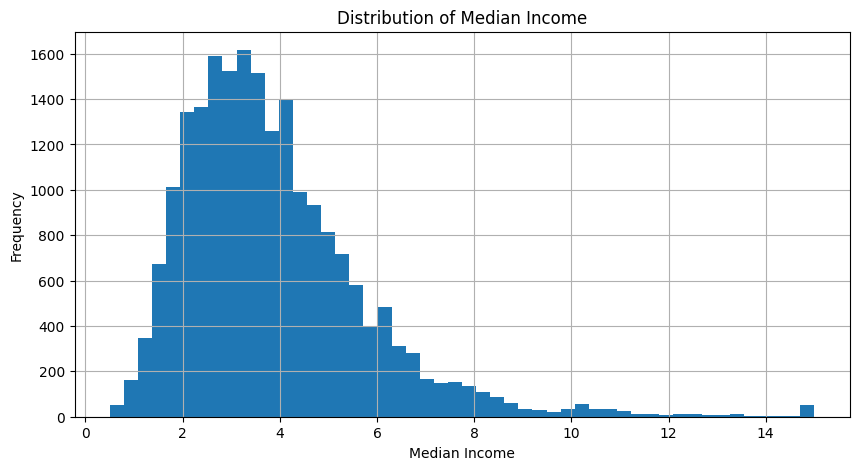

In [10]:
#visualize the data

plt.figure(figsize = (10, 5))

housing["median_income"].hist(bins=50)

plt.title("Distribution of Median Income")
plt.xlabel("Median Income")
plt.ylabel("Frequency")

plt.show()

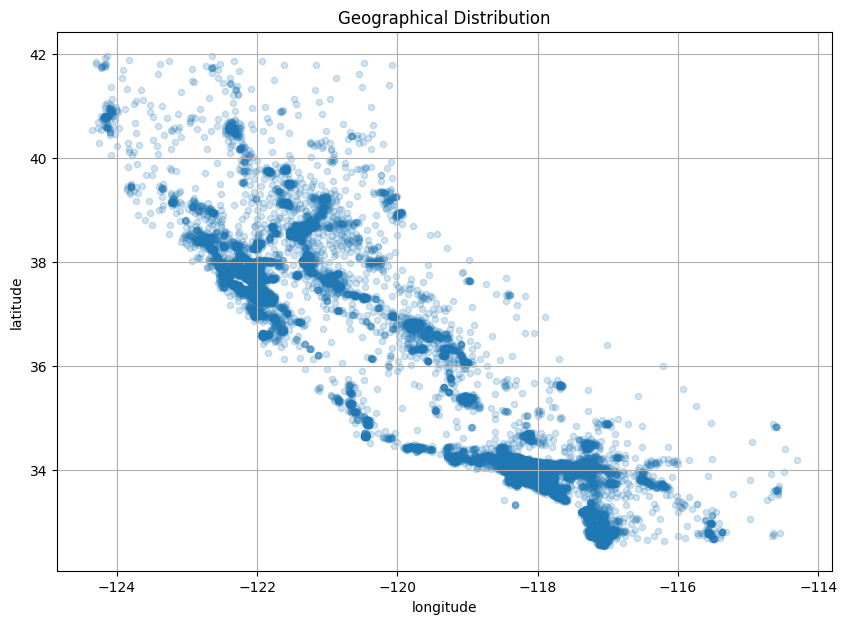

In [11]:
#geographical scatter plot

housing.plot(
    kind = "scatter",
    x = "longitude",
    y = "latitude",
    grid = True,
    alpha = 0.2,
    figsize = (10, 7)
)

plt.title("Geographical Distribution")
plt.show()

In [12]:
#correlaton matrix
#helps us understand how strongly two numerical values are related

corr_matrix = housing.corr(numeric_only=True)

print(
    corr_matrix["median_house_value"].sort_values(ascending=False)
)

median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64


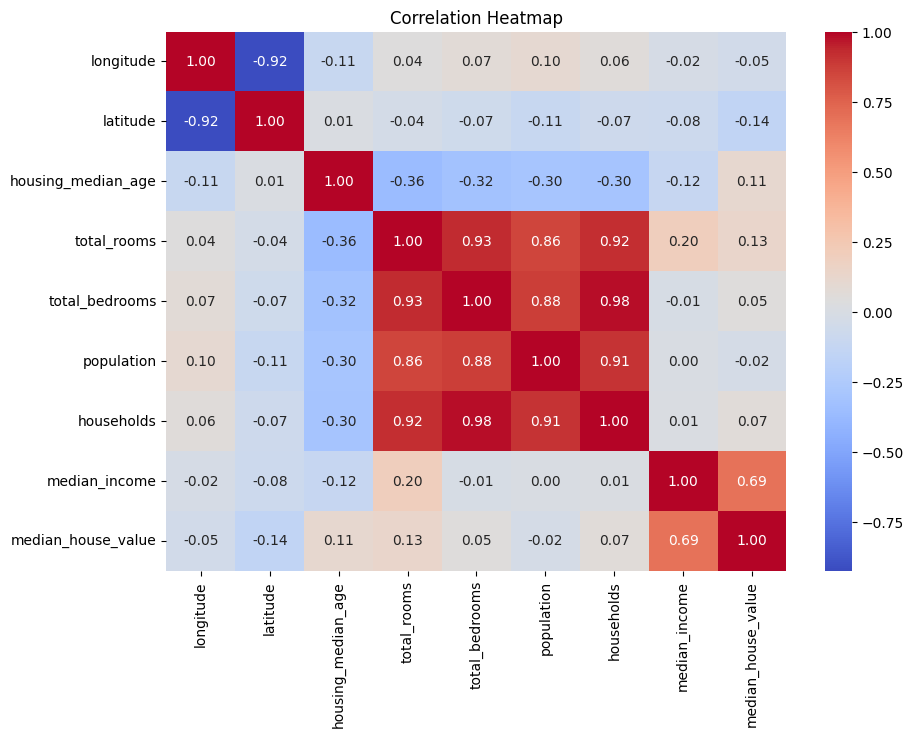

In [13]:
#visualize the correlation matrix

plt.figure(figsize = (10, 7))

sns.heatmap(
    corr_matrix,
    annot = True,
    cmap = "coolwarm",
    fmt = ".2f"
)

plt.title("Correlation Heatmap")
plt.show()

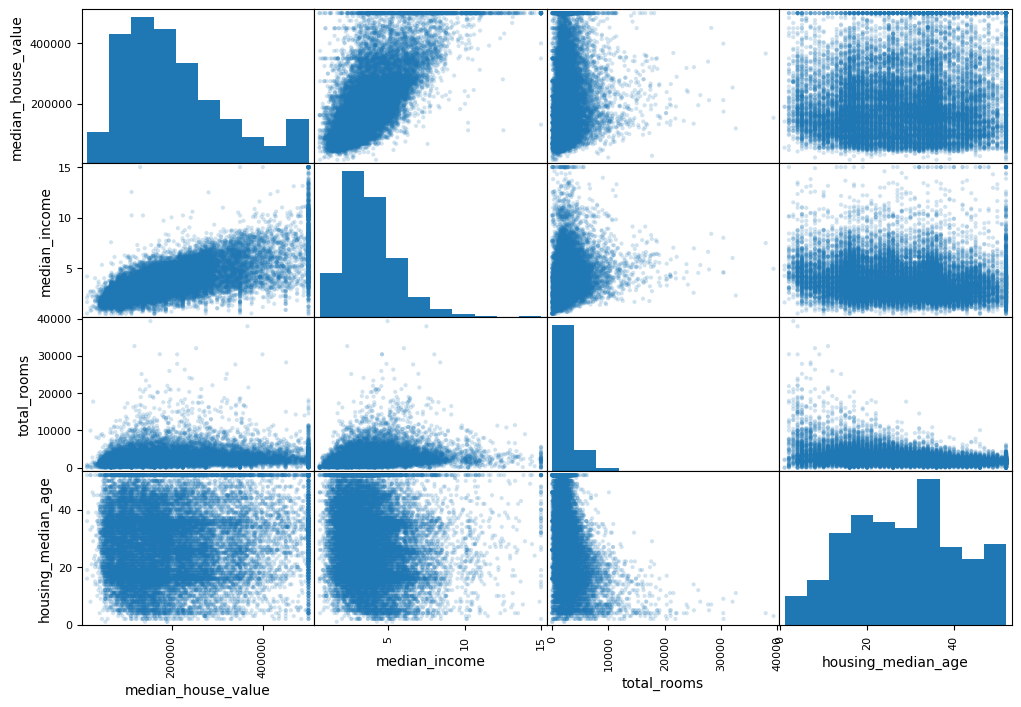

In [14]:
#examine relation between multiple features using sactter matrix
from pandas.plotting import scatter_matrix

attributes = [
    "median_house_value",
    "median_income",
    "total_rooms",
    "housing_median_age"
]

scatter_matrix(
    housing[attributes],
    figsize = (12, 8),
    alpha = 0.2
)

plt.show()

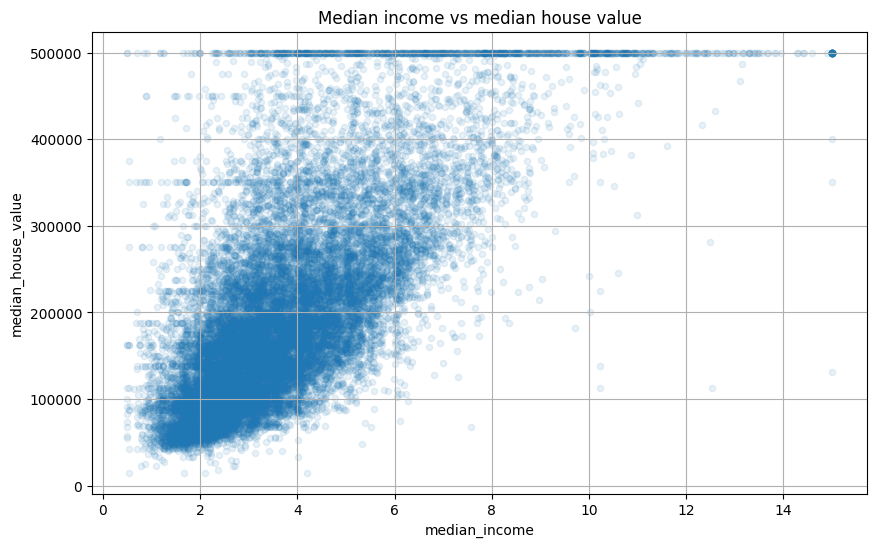

In [15]:
#check income and house price

housing.plot(
    kind = "scatter",
    x = "median_income",
    y = "median_house_value",
    alpha = 0.1,
    grid = True,
    figsize = (10, 6)
)

plt.title("Median income vs median house value")
plt.show()

In [16]:
#random sampling

def shuffle_and_split_data(data, test_ratio):

  np.random.seed(42)

  shuffled_indices = np.random.permutation(len(data))
  test_set_size = int(len(data) * test_ratio)
  test_indices = shuffled_indices[:test_set_size]
  train_indices = shuffled_indices[test_set_size:]

  return data.iloc[train_indices], data.iloc[test_indices]

In [17]:
#test random sampling

train_set, test_set = shuffle_and_split_data(
    housing,
    test_ratio=0.2
)

print("Training records:", len(train_set))
print("Testing records:", len(test_set))

Training records: 16512
Testing records: 4128


Why isn't random sampling always enough?
Imagine our dataset has the following income distribution:
- Low-income areas.
- Medium-income areas.
- High-income areas.
Suppose our random split accidentally places too many high-income observations in the training set and too few in the testing set.

Our testing data might no longer represent the original population properly.

This is called sampling bias.

To reduce this problem, we use Stratified Sampling.

In [18]:
#create income categories

housing["income_cat"] = pd.cut(
    housing["median_income"],
    bins=[0, 1.5, 3.0, 4.5, 6.0, np.inf],
    labels=[1, 2, 3, 4, 5]
)

housing["income_cat"].value_counts().sort_index()

,count
income_cat,
1,822
2,6581
3,7236
4,3639
5,2362


In [19]:
#implement the startifies shuffle split

from sklearn.model_selection import StratifiedShuffleSplit

split = StratifiedShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

for train_index, test_index in split.split(
    housing, housing["income_cat"]
):

    strat_train_set = housing.loc[train_index].drop(
        "income_cat", axis=1
    )

    strat_test_set = housing.loc[test_index].drop(
        "income_cat", axis=1
    )

print("Training records:", len(strat_train_set))
print("Testing records:", len(strat_test_set))

Training records: 16512
Testing records: 4128


Distribution maintained successfully using StratifiedShuffleSplit

In [20]:
# Original income distribution
original_dist = housing["income_cat"].value_counts(
    normalize=True
).sort_index()

# Training income distribution
train_dist = strat_train_set["median_income"]

train_dist = pd.cut(
    train_dist,
    bins=[0, 1.5, 3.0, 4.5, 6.0, np.inf],
    labels=[1, 2, 3, 4, 5]
).value_counts(normalize=True).sort_index()

# Testing income distribution
test_dist = strat_test_set["median_income"]

test_dist = pd.cut(
    test_dist,
    bins=[0, 1.5, 3.0, 4.5, 6.0, np.inf],
    labels=[1, 2, 3, 4, 5]
).value_counts(normalize=True).sort_index()

comparison = pd.DataFrame({
    "Original": original_dist,
    "Training": train_dist,
    "Testing": test_dist
})

print(comparison)

   Original  Training   Testing
1  0.039826  0.039789  0.039971
2  0.318847  0.318859  0.318798
3  0.350581  0.350594  0.350533
4  0.176308  0.176296  0.176357
5  0.114438  0.114462  0.114341


Data Preprocessing

In [21]:
#create copy of the original training dataset
housing = strat_train_set.copy()

#separate the target variables
housing_labels = housing["median_house_value"].copy()

housing = housing.drop(
    "median_house_value",
    axis=1
)

print("Features shape:", housing.shape)
print("Labels shape:", housing_labels.shape)

Features shape: (16512, 9)
Labels shape: (16512,)


In [22]:
#check missing values

housing.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,158
population,0
households,0
median_income,0
ocean_proximity,0


Imputation: Instead of dropping missing values we can calculate its median so that we can get a average or an estimation of the missing values. For e.g. finding median

In [23]:
#import simple imputer
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy = "median")

#select the numerical columns
housing_num = housing.select_dtypes(
    include=[np.number]
)

#fit and calculate the median values
imputer.fit(housing_num)

SimpleImputer(strategy='median')

In [24]:
#inspect the learned medians
imputer.statistics_

array([-118.51   ,   34.26   ,   29.     , 2119.     ,  433.     ,
       1164.     ,  408.     ,    3.54155])

In [25]:
#using the transform

#NOTE: X is an np array
X = imputer.transform(housing_num)

print("Original shape:", housing_num.shape)
print("Transformed shape:", X.shape)

Original shape: (16512, 8)
Transformed shape: (16512, 8)


In [26]:
#check if the missing values are gone or not

print("Missing values before:", housing_num.isnull().sum().sum())

print("Missing values after:", np.isnan(X).sum())

Missing values before: 158
Missing values after: 0


In [27]:
#convert back to dataframe

housing_tr = pd.DataFrame(
    X,
    columns=housing_num.columns,
    index=housing_num.index
)

housing_tr.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
12655,-121.46,38.52,29.0,3873.0,797.0,2237.0,706.0,2.1736
15502,-117.23,33.09,7.0,5320.0,855.0,2015.0,768.0,6.3373
2908,-119.04,35.37,44.0,1618.0,310.0,667.0,300.0,2.8750
14053,-117.13,32.75,24.0,1877.0,519.0,898.0,483.0,2.2264
20496,-118.70,34.28,27.0,3536.0,646.0,1837.0,580.0,4.4964


In [28]:
pd.Series(
    imputer.statistics_,
    index=housing_num.columns
)

,0
longitude,-118.51000
latitude,34.26000
housing_median_age,29.00000
total_rooms,2119.00000
total_bedrooms,433.00000
population,1164.00000
households,408.00000
median_income,3.54155


In [29]:
# Check missing values before and after imputation
print("Missing values before:", housing_num.isnull().sum().sum())
print("Missing values after:", np.isnan(X).sum())

# Display the median learned for each numerical column
print("\nMedians learned by the imputer:")
print(pd.Series(imputer.statistics_, index=housing_num.columns))

Missing values before: 158
Missing values after: 0

Medians learned by the imputer:
longitude             -118.51000
latitude                34.26000
housing_median_age      29.00000
total_rooms           2119.00000
total_bedrooms         433.00000
population            1164.00000
households             408.00000
median_income            3.54155
dtype: float64


Understanding categorial data

Use of OneHotEncoder

In [30]:
#select the categorial column
housing_cat = housing[["ocean_proximity"]]

housing_cat.head()

,ocean_proximity
12655,INLAND
15502,NEAR OCEAN
2908,INLAND
14053,NEAR OCEAN
20496,<1H OCEAN


In [31]:
housing_cat["ocean_proximity"].value_counts()

,count
ocean_proximity,
<1H OCEAN,7277
INLAND,5262
NEAR OCEAN,2124
NEAR BAY,1847
ISLAND,2


Use onehotencoder to convert non numerical measurements to numerical inputs so that the model can learn.

OneHotEncoder converts each category into a separate binary feature, allowing the model to use this information without assuming any natural ordering."

Why we are doing this?

this project predicts the prices of the houses. so its important to know its location as place is also a factor of price determination of houses.

In [32]:
#Implement, one hot encoder

from sklearn.preprocessing import OneHotEncoder

#create the encoder
cat_encoder = OneHotEncoder()

#Fit and transform the data
housing_cat_one_hot = cat_encoder.fit_transform(housing_cat)

#Display the result
print("Encoded shape:", housing_cat_one_hot.shape)

Encoded shape: (16512, 5)


In [33]:
# See the categories learned by the encoder
print("Categories:", cat_encoder.categories_)

# Convert sparse matrix into a normal array for viewing
print(housing_cat_one_hot.toarray()[:10])

Categories: [array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
      dtype=object)]
[[0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 1.]
 [0. 1. 0. 0. 0.]
 [0. 0. 0. 0. 1.]
 [1. 0. 0. 0. 0.]
 [0. 0. 0. 1. 0.]
 [1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0.]]


Feature scaling:
Before training models, we need to understand why numerical features may require scaling.

Consider these two columns:
Feature	Example value
median_income	8.3
population	1,200

Their numerical ranges are very different.

Some machine learning algorithms can be affected by these differences in scale. For example, Linear Regression with certain optimization methods and distance-based algorithms can benefit from scaling.

We will use standard scaler here

In [34]:
#implement standard scaler
from sklearn.preprocessing import StandardScaler

#create the scaler
std_scaler = StandardScaler()

In [35]:
#standardize the imputed numerical features
housing_num_std_scaled = std_scaler.fit_transform(housing_tr)

print("Original shape:", housing_tr.shape)
print("Scaled shape:", housing_num_std_scaled.shape)

print("\nFirst 5 scaled records:")
print(housing_num_std_scaled[:5].round(2))

Original shape: (16512, 8)
Scaled shape: (16512, 8)

First 5 scaled records:
[[-0.94  1.35  0.03  0.58  0.64  0.73  0.56 -0.89]
 [ 1.17 -1.19 -1.72  1.26  0.78  0.53  0.72  1.29]
 [ 0.27 -0.13  1.22 -0.47 -0.55 -0.67 -0.52 -0.53]
 [ 1.22 -1.35 -0.37 -0.35 -0.04 -0.47 -0.04 -0.87]
 [ 0.44 -0.64 -0.13  0.43  0.27  0.37  0.22  0.33]]


In [36]:
#check whether mean is 0 and standard deviations are 1 approximately
print("Column means:")
print(housing_num_std_scaled.mean(axis=0).round(2))

print("\nColumn standard deviations:")
print(housing_num_std_scaled.std(axis=0).round(2))

Column means:
[ 0.  0.  0. -0. -0. -0. -0. -0.]

Column standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1.]


Build a Numerical Pipeline

In [37]:
#create the pipeline
from sklearn.pipeline import Pipeline

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("std_scaler", StandardScaler())
])

In [38]:
#apply the pipeline
housing_num_prepared = num_pipeline.fit_transform(housing_num)

print("Prepared shape:", housing_num_prepared.shape)
print("\nFirst 5 records:")
print(housing_num_prepared[:5].round(2))

Prepared shape: (16512, 8)

First 5 records:
[[-0.94  1.35  0.03  0.58  0.64  0.73  0.56 -0.89]
 [ 1.17 -1.19 -1.72  1.26  0.78  0.53  0.72  1.29]
 [ 0.27 -0.13  1.22 -0.47 -0.55 -0.67 -0.52 -0.53]
 [ 1.22 -1.35 -0.37 -0.35 -0.04 -0.47 -0.04 -0.87]
 [ 0.44 -0.64 -0.13  0.43  0.27  0.37  0.22  0.33]]


Combine everything using ColumnTransformer

In [39]:
# Identify numerical columns
num_attribs = housing_num.columns.tolist()

# Identify categorical columns
cat_attribs = ["ocean_proximity"]

print("Numerical columns:", num_attribs)
print("\nCategorical columns:", cat_attribs)

Numerical columns: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']

Categorical columns: ['ocean_proximity']


ColumnTransformer needs to know which columns should go through each pipeline

In [41]:
#Create the categorical pipeline

cat_pipeline = Pipeline([
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

#What is handle_unknown="ignore"?

# Imagine that our training data contains five categories, but future data contains a new category that the encoder has never seen.

# Without this setting, the encoder can raise an error.

# With handle_unknown="ignore", it handles an unseen category without raising that error. Its encoded values will be all zeros for that categorical feature.

- "num": name of the transformation.
- num_pipeline: numerical preprocessing workflow.
- num_attribs: columns to which it applies.

The categorical tuple works the same way.

In [43]:
#combine both the pipelines

from sklearn.compose import ColumnTransformer

full_pipeline = ColumnTransformer([
    ("num", num_pipeline, num_attribs),
    ("cat", cat_pipeline, cat_attribs)
])

The 13 features are:
- 8 standardized numerical features.
- 5 one-hot encoded categorical features.

In [44]:
#Apply the complete preprocessing pipeline

housing_prepared = full_pipeline.fit_transform(housing)

print("Prepared dataset shape:", housing_prepared.shape)

Prepared dataset shape: (16512, 13)


TRAINING DIFFERENT MODELS

In [45]:
#import required models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

# **Train the three models**

housing_prepared: the 13 input features.



housing_labels: the actual house prices.



fit(): learns patterns from the input features and their corresponding house prices.

In [46]:
# Linear Regression
lin_reg = LinearRegression()
lin_reg.fit(housing_prepared, housing_labels)

# Decision Tree
tree_reg = DecisionTreeRegressor(random_state=42)
tree_reg.fit(housing_prepared, housing_labels)

# Random Forest
forest_reg = RandomForestRegressor(random_state=42)
forest_reg.fit(housing_prepared, housing_labels)

RandomForestRegressor(random_state=42)

Make predictions on training data

In [47]:
lin_preds = lin_reg.predict(housing_prepared)
tree_preds = tree_reg.predict(housing_prepared)
forest_preds = forest_reg.predict(housing_prepared)

In [48]:
#calculate the RMSE

lin_rmse = np.sqrt(mean_squared_error(housing_labels, lin_preds))

tree_rmse = np.sqrt(mean_squared_error(housing_labels, tree_preds))

forest_rmse = np.sqrt(mean_squared_error(housing_labels, forest_preds))

print("Linear Regression RMSE:", lin_rmse)
print("Decision Tree RMSE:", tree_rmse)
print("Random Forest RMSE:", forest_rmse)

Linear Regression RMSE: 69050.56219504567
Decision Tree RMSE: 0.0
Random Forest RMSE: 18342.366362322846


RMSE is not the only way to estimate the model. So we will use another method called as **cross validation.**

What cross validation does is it divides the training data to certain folds (say 10 called 10 fold cross validation).

It trains on 9 parts and validate on the remaining part.

This process continues till every part turns to validation part.

Later it calculates the avg performance

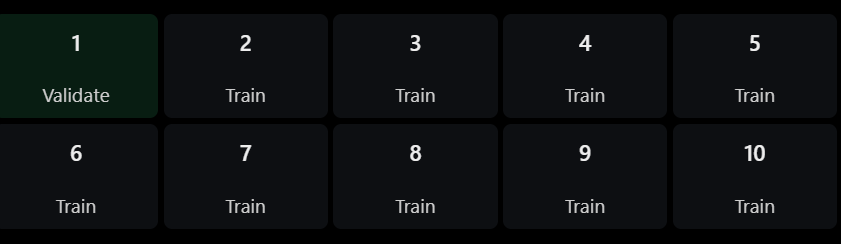

Why does Scikit-learn return negative RMSE?

Scikit-learn follows a scoring convention where higher scores are better. Since lower RMSE is better, it returns negative RMSE so that a less negative score represents better performance.

In [49]:
#cross validate decision tree

from sklearn.model_selection import cross_val_score

tree_rmses = -cross_val_score(
    tree_reg, #Decision Tree model
    housing_prepared, #contains the 13 prepared features.
    housing_labels, #Decision Tree model.
    scoring="neg_root_mean_squared_error", #requests RMSE-based scoring
    cv=10 #10 folds
)

print("Decision Tree CV RMSEs:", tree_rmses)

print("\nCross-Validation Performance:")
print(pd.Series(tree_rmses).describe())

Decision Tree CV RMSEs: [71177.6601991  69770.07865373 64770.5639395  68536.60203993
 67057.08155801 68847.12456973 70977.38255647 69208.86346929
 67187.87131535 73280.38732407]

Cross-Validation Performance:
count       10.000000
mean     69081.361563
std       2420.500173
min      64770.563939
25%      67525.053996
50%      69027.994020
75%      70675.556581
max      73280.387324
dtype: float64


Cross validate other models

In [50]:
# Linear Regression cross-validation
lin_rmses = -cross_val_score(
    lin_reg,
    housing_prepared,
    housing_labels,
    scoring="neg_root_mean_squared_error",
    cv=10
)

# Random Forest cross-validation
forest_rmses = -cross_val_score(
    forest_reg,
    housing_prepared,
    housing_labels,
    scoring="neg_root_mean_squared_error",
    cv=10
)

print("Linear Regression CV RMSE:", lin_rmses.mean())
print("Decision Tree CV RMSE:", tree_rmses.mean())
print("Random Forest CV RMSE:", forest_rmses.mean())

Linear Regression CV RMSE: 69204.32275494763
Decision Tree CV RMSE: 69081.361562518
Random Forest CV RMSE: 49432.12678796127


An important improvement before choosing our model
There's one methodological issue we should fix.

Until now, we fitted full_pipeline on all 16,512 training records before performing cross-validation. That means the imputer, scaler and encoder learned information from records that later became validation folds.

This is a form of data leakage.

To get a more reliable comparison, we'll put preprocessing and the model inside one pipeline. Each cross-validation fold will then learn its own preprocessing statistics using only its training portion.

In [51]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

# Combine preprocessing and Linear Regression
lin_full_pipeline = Pipeline([
    ("preprocessing", full_pipeline),
    ("model", LinearRegression())
])

# Combine preprocessing and Decision Tree
tree_full_pipeline = Pipeline([
    ("preprocessing", full_pipeline),
    ("model", DecisionTreeRegressor(random_state=42))
])

# Combine preprocessing and Random Forest
forest_full_pipeline = Pipeline([
    ("preprocessing", full_pipeline),
    ("model", RandomForestRegressor(random_state=42))
])

Now run cross-validation using the original training features, not the already transformed data:

In [52]:
lin_scores = -cross_val_score(
    lin_full_pipeline,
    housing,
    housing_labels,
    scoring="neg_root_mean_squared_error",
    cv=10
)

tree_scores = -cross_val_score(
    tree_full_pipeline,
    housing,
    housing_labels,
    scoring="neg_root_mean_squared_error",
    cv=10
)

forest_scores = -cross_val_score(
    forest_full_pipeline,
    housing,
    housing_labels,
    scoring="neg_root_mean_squared_error",
    cv=10
)

print("Linear Regression:", lin_scores.mean())
print("Decision Tree:", tree_scores.mean())
print("Random Forest:", forest_scores.mean())

Linear Regression: 69204.32092215857
Decision Tree: 69072.80553705241
Random Forest: 49397.56033707019


Random forest performs best here so we are going to evaluate random forest at the end

In [53]:
# Separate test features and target labels
X_test = strat_test_set.drop("median_house_value", axis=1)

y_test = strat_test_set["median_house_value"].copy()

print("Test features shape:", X_test.shape)
print("Test labels shape:", y_test.shape)

Test features shape: (4128, 9)
Test labels shape: (4128,)


The 13 columns are 8 numerical features plus 5 one-hot encoded categorical features.

In [55]:
#Transform the test data

X_test_prepared = full_pipeline.transform(X_test)
print("Prepared test data shape:", X_test_prepared.shape)

Prepared test data shape: (4128, 13)


Testing

In [56]:
#Generate predictions
final_predictions = forest_reg.predict(X_test_prepared)

print("First 10 actual prices:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted prices:")
print(final_predictions[:10])

First 10 actual prices:
[500001. 162500. 204600. 159700. 184000. 151900. 104900. 500001. 367400.
 346500.]

First 10 predicted prices:
[483020.6  221708.09 205706.   170623.   212497.   164798.   114046.
 434144.28 280961.03 258439.07]


In [57]:
#Evaluate the model
from sklearn.metrics import mean_squared_error, mean_absolute_error

final_rmse = np.sqrt(mean_squared_error(y_test, final_predictions))
final_mae = mean_absolute_error(y_test, final_predictions)

print("Final Test RMSE:", final_rmse)
print("Final Test MAE:", final_mae)

Final Test RMSE: 47197.66824186381
Final Test MAE: 30929.476097383722


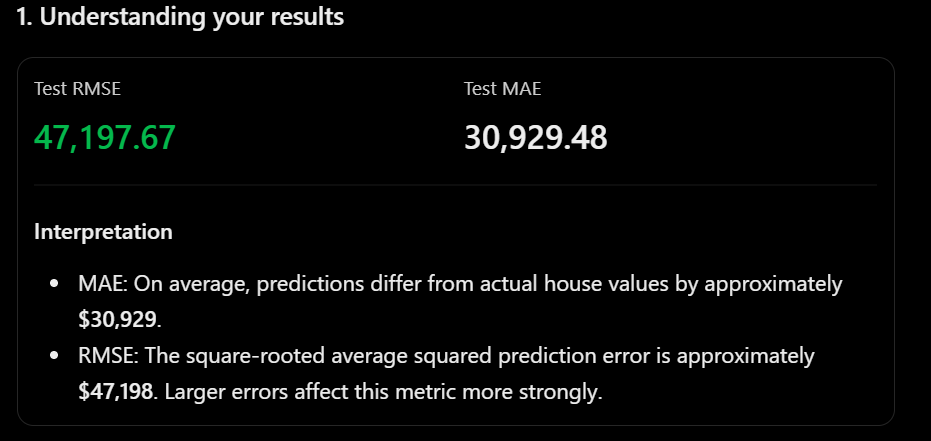

Use joblib to save the model

Suppose tomorrow you receive new housing data. It will need the same missing-value handling, scaling and categorical encoding as the training data.

The saved pipeline ensures those transformations remain consistent. The saved model then generates predictions.

What is Joblib?

Joblib is a Python library that serializes Python objects, meaning it saves them to files so they can be loaded and reused later.

In [61]:
#Save your trained model
import joblib

#save the trained random forest model
joblib.dump(forest_reg, 'model.pkl')

#save the fitted preprocessing pipeline
joblib.dump(full_pipeline, 'pipeline.pkl')

print("Model and preprocessing pipeline saved successfully!")

Model and preprocessing pipeline saved successfully!


In [64]:
# verify the saved model
import os

print("Model file size:", os.path.getsize("model.pkl"))
print("pipeline file size:", os.path.getsize("pipeline.pkl"))

Model file size: 144299809
pipeline file size: 4501


In [65]:
print("Model file exists:", os.path.exists("model.pkl"))
print("Pipeline file exists:", os.path.exists("pipeline.pkl"))

Model file exists: True
Pipeline file exists: True


Load the saved model

In [66]:
# Load saved model and preprocessing pipeline
loaded_model = joblib.load("model.pkl")
loaded_pipeline = joblib.load("pipeline.pkl")

print("Model loaded successfully!")
print("Pipeline loaded successfully!")

Model loaded successfully!
Pipeline loaded successfully!


Create another cell to test inference using the first five records from our test dataset:

In [67]:
# Select five raw test records
sample_data = X_test.iloc[:5].copy()

# Apply saved preprocessing pipeline
sample_prepared = loaded_pipeline.transform(sample_data)

# Generate predictions
sample_predictions = loaded_model.predict(sample_prepared)

# Compare actual and predicted prices
comparison = pd.DataFrame({
    "Actual Price": y_test.iloc[:5].values,
    "Predicted Price": sample_predictions
})

comparison

,Actual Price,Predicted Price
0,500001.0,483020.60
1,162500.0,221708.09
2,204600.0,205706.00
3,159700.0,170623.00
4,184000.0,212497.00
